<a href="https://colab.research.google.com/github/vaideheedaf/ML-Coral-reef/blob/main/SVM_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


In [2]:
# Load the provided datasets
train_df = pd.read_csv("/content/ML_train.csv")
valid_df = pd.read_csv("/content/ML_valid.csv")
test_df = pd.read_csv("/content/ML_test.csv")

print("Training set shape:", train_df.shape)
print("Validation set shape:", valid_df.shape)
print("Test set shape:", test_df.shape)

display(train_df.head())


Training set shape: (9662, 12)
Validation set shape: (463, 12)
Test set shape: (257, 12)


,image_id,image_path,mean_saturation,mean_brightness,white_pixel_pct,mean_lightness,lbp_mean,glcm_contrast,glcm_homogeneity,edge_density,entropy,target
0,train_img1,train/Bleached/youtube-100_jpg.rf.0dabe0db90cb...,99.002151,126.100815,14.497375,113.029327,4.951385,815.653529,0.183843,0.221130,7.748362,Bleached
1,train_img2,train/Bleached/youtube-100_jpg.rf.54a309a4c4c9...,92.206512,115.301987,13.388062,104.026047,5.033081,744.556724,0.196752,0.211090,7.593638,Bleached
2,train_img3,train/Bleached/youtube-100_jpg.rf.565dc914caf0...,108.078598,96.078415,8.157349,83.416687,5.083466,784.028821,0.210820,0.207916,7.393996,Bleached
3,train_img4,train/Bleached/youtube-100_jpg.rf.7e092c5799d6...,94.855270,116.346756,13.096619,104.714050,5.001160,753.257625,0.190292,0.215714,7.624984,Bleached
4,train_img5,train/Bleached/youtube-100_jpg.rf.ace204326a26...,91.040375,135.027679,17.640686,122.591599,4.930664,771.843070,0.176914,0.225037,7.780398,Bleached


In [3]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTraining data types:")
print(train_df.dtypes)

print("\nMissing values:")
display(train_df.isnull().sum())

print("\nTarget distribution - Training:")
display(train_df["target"].value_counts())

print("\nTarget distribution - Validation:")
display(valid_df["target"].value_counts())

print("\nTarget distribution - Test:")
display(test_df["target"].value_counts())


Training columns:
['image_id', 'image_path', 'mean_saturation', 'mean_brightness', 'white_pixel_pct', 'mean_lightness', 'lbp_mean', 'glcm_contrast', 'glcm_homogeneity', 'edge_density', 'entropy', 'target']

Training data types:
image_id             object
image_path           object
mean_saturation     float64
mean_brightness     float64
white_pixel_pct     float64
mean_lightness      float64
lbp_mean            float64
glcm_contrast       float64
glcm_homogeneity    float64
edge_density        float64
entropy             float64
target               object
dtype: object

Missing values:


,0
image_id,0
image_path,0
mean_saturation,0
mean_brightness,0
white_pixel_pct,0
mean_lightness,0
lbp_mean,0
glcm_contrast,0
glcm_homogeneity,0
edge_density,0



Target distribution - Training:


,count
target,
Bleached,4980
Healthy,4682



Target distribution - Validation:


,count
target,
Bleached,240
Healthy,223



Target distribution - Test:


,count
target,
Bleached,135
Healthy,122


In [4]:
feature_cols = [
    "mean_saturation",
    "mean_brightness",
    "white_pixel_pct",
    "mean_lightness",
    "lbp_mean",
    "glcm_contrast",
    "glcm_homogeneity",
    "edge_density",
    "entropy"
]

target_col = "target"

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_valid = valid_df[feature_cols]
y_valid = valid_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

print("Number of features:", len(feature_cols))
print("Features:", feature_cols)


Number of features: 9
Features: ['mean_saturation', 'mean_brightness', 'white_pixel_pct', 'mean_lightness', 'lbp_mean', 'glcm_contrast', 'glcm_homogeneity', 'edge_density', 'entropy']


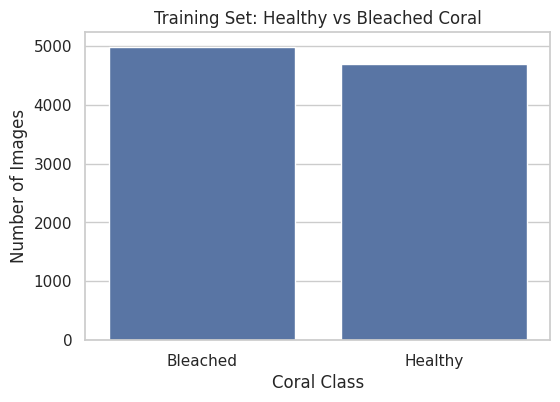

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x="target")
plt.title("Training Set: Healthy vs Bleached Coral")
plt.xlabel("Coral Class")
plt.ylabel("Number of Images")
plt.show()


In [6]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

# Train on training data only
svm_model.fit(X_train, y_train)

print("SVM model trained successfully.")


SVM model trained successfully.


In [7]:
y_valid_pred = svm_model.predict(X_valid)

valid_accuracy = accuracy_score(y_valid, y_valid_pred)
valid_precision = precision_score(
    y_valid, y_valid_pred, pos_label="Healthy", zero_division=0
)
valid_recall = recall_score(
    y_valid, y_valid_pred, pos_label="Healthy", zero_division=0
)
valid_f1 = f1_score(
    y_valid, y_valid_pred, pos_label="Healthy", zero_division=0
)

validation_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        valid_accuracy,
        valid_precision,
        valid_recall,
        valid_f1
    ]
})

display(validation_metrics.round(4))


,Metric,Score
0,Accuracy,0.9222
1,Precision,0.9231
2,Recall,0.9148
3,F1-score,0.9189


In [8]:
# Combine training and validation data for the final model
X_train_final = pd.concat([X_train, X_valid], ignore_index=True)
y_train_final = pd.concat([y_train, y_valid], ignore_index=True)

final_svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

final_svm_model.fit(X_train_final, y_train_final)

# Predict on the untouched test set
y_test_pred = final_svm_model.predict(X_test)

print("Final SVM trained on training + validation data.")
print("Test predictions generated.")


Final SVM trained on training + validation data.
Test predictions generated.


In [9]:
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(
    y_test, y_test_pred, pos_label="Healthy", zero_division=0
)
test_recall = recall_score(
    y_test, y_test_pred, pos_label="Healthy", zero_division=0
)
test_f1 = f1_score(
    y_test, y_test_pred, pos_label="Healthy", zero_division=0
)

test_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(test_metrics.round(4))


,Metric,Score
0,Accuracy,0.9183
1,Precision,0.9316
2,Recall,0.8934
3,F1-score,0.9121


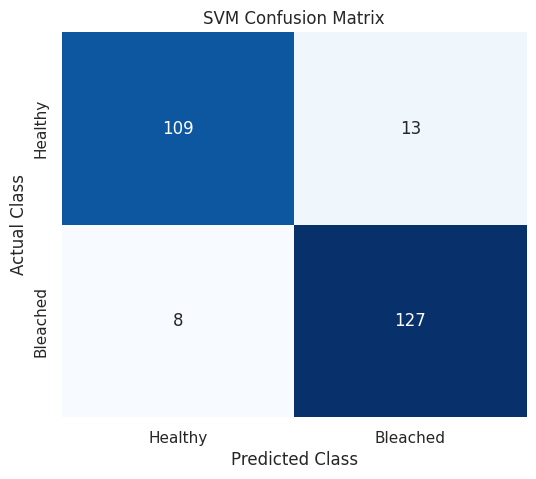

In [10]:
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["Healthy", "Bleached"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Healthy", "Bleached"],
    yticklabels=["Healthy", "Bleached"]
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


In [11]:
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=["Healthy", "Bleached"],
        target_names=["Healthy", "Bleached"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

     Healthy       0.93      0.89      0.91       122
    Bleached       0.91      0.94      0.92       135

    accuracy                           0.92       257
   macro avg       0.92      0.92      0.92       257
weighted avg       0.92      0.92      0.92       257



In [12]:
results = test_df[["image_id", "target"]].copy()
results["predicted"] = y_test_pred
results["correct"] = results["target"] == results["predicted"]

display(results.head(20))

print("Correct predictions:", results["correct"].sum())
print("Incorrect predictions:", (~results["correct"]).sum())


,image_id,target,predicted,correct
0,test_img1,Bleached,Bleached,True
1,test_img2,Bleached,Healthy,False
2,test_img3,Bleached,Bleached,True
3,test_img4,Bleached,Bleached,True
4,test_img5,Bleached,Bleached,True
5,test_img6,Bleached,Bleached,True
6,test_img7,Bleached,Bleached,True
7,test_img8,Bleached,Bleached,True
8,test_img9,Bleached,Bleached,True
9,test_img10,Bleached,Bleached,True


Correct predictions: 236
Incorrect predictions: 21
